# Task 2 — Netflix Shows Analysis

**Question:** What does the supplied Netflix catalog snapshot show about content types, genres, countries, contributors, dates, ratings and duration?

**Answer:** This EDA analyzes unique catalog titles, with explicit cleaning and separate duration units for films and series. Run cells in order; the source CSV is included.

Source: https://www.kaggle.com/datasets/shivamb/netflix-shows  
File: `netflix_titles.csv`, retrieved 5 November 2026. The addition dates end in September 2021. This is a historical catalog snapshot, not Netflix's current catalog or a viewing-performance dataset.

## 1. Load and inspect

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

candidates = [Path.cwd(), Path.cwd() / '02_Netflix_Shows', Path.cwd() / 'Solution_Task_25' / '02_Netflix_Shows']
BASE = next((p for p in candidates if (p / 'data' / 'netflix_titles.csv').is_file()), Path.cwd())
DATA_PATH = BASE / 'data' / 'netflix_titles.csv'  # Change this path for another local copy.
FIGURES = BASE / 'figures'
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 20)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches='tight')
    plt.show()

raw = pd.read_csv(DATA_PATH)
print('Rows, columns:', raw.shape)
display(raw.head())
raw.info()


Rows, columns: (8807, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
display(raw.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Exact duplicates:', raw.duplicated().sum())
print('Repeated show IDs:', raw['show_id'].duplicated().sum())
display(raw.describe(include='all'))

Exact duplicates: 0
Repeated show IDs: 0


,missing
director,2634
country,831
cast,825
date_added,10
rating,4
duration,3
show_id,0
type,0
title,0
release_year,0


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


## 2. Clean the data

Strip text, remove exact duplicates and validate unique show IDs. Repair a duration stored in `rating` only when it matches a minutes pattern and `duration` is missing. Retain unknown director/cast/country rather than guessing. Parse dates and numeric years; keep missing dates out of time analyses. Split movie minutes and TV seasons into different variables. Negative release-to-addition year gaps are flagged and excluded from lag summaries, without deleting the title.

In [3]:
shows = raw.copy()
for col in shows.select_dtypes(include='object'):
    shows[col] = shows[col].astype('string').str.strip().replace('', pd.NA)
exact_duplicates = int(shows.duplicated().sum())
shows = shows.drop_duplicates().copy()
if shows['show_id'].duplicated().any():
    raise ValueError('Conflicting repeated show_id values need manual review.')
repair = shows['duration'].isna() & shows['rating'].str.fullmatch(r'\d+\s+min', na=False)
repaired_count = int(repair.sum())
shows.loc[repair, 'duration'] = shows.loc[repair, 'rating']
shows.loc[repair, 'rating'] = pd.NA
missing_before_fill = shows[['director', 'cast', 'country', 'rating']].isna().sum()
shows['date_added'] = pd.to_datetime(shows['date_added'], format='%B %d, %Y', errors='coerce')
shows['release_year'] = pd.to_numeric(shows['release_year'], errors='coerce').astype('Int64')
shows.loc[~shows['release_year'].between(1800, 2021).fillna(False), 'release_year'] = pd.NA
shows['added_year'] = shows['date_added'].dt.year.astype('Int64')
parsed = shows['duration'].str.extract(r'^(\d+)\s+(min|Season|Seasons)$')
amount = pd.to_numeric(parsed[0], errors='coerce')
shows['duration_value'] = amount.where(amount.gt(0)).astype('Int64')
shows['duration_unit'] = parsed[1].replace({'min': 'minutes', 'Season': 'seasons', 'Seasons': 'seasons'})
shows['movie_minutes'] = shows['duration_value'].where(shows['type'].eq('Movie') & shows['duration_unit'].eq('minutes'))
shows['tv_seasons'] = shows['duration_value'].where(shows['type'].eq('TV Show') & shows['duration_unit'].eq('seasons'))
shows['release_to_add_years'] = shows['added_year'] - shows['release_year']
negative_lags = int(shows['release_to_add_years'].lt(0).sum())
shows['valid_lag_years'] = shows['release_to_add_years'].where(shows['release_to_add_years'].ge(0))
for col in ['director', 'cast', 'country', 'rating']:
    shows[col] = shows[col].fillna('Unknown')
cleaning = pd.Series({'raw_rows': len(raw), 'clean_rows': len(shows), 'duplicates_removed': exact_duplicates,
    'misplaced_durations_repaired': repaired_count, 'missing_added_date': shows['date_added'].isna().sum(),
    'unknown_ratings': shows['rating'].eq('Unknown').sum(), 'negative_year_lags_flagged': negative_lags})
display(cleaning.to_frame('value'))
display(missing_before_fill.to_frame('missing_contributor_or_category'))
display(shows.loc[repair, ['title', 'rating', 'duration', 'movie_minutes']])


,value
raw_rows,8807
clean_rows,8807
duplicates_removed,0
misplaced_durations_repaired,3
missing_added_date,10
unknown_ratings,7
negative_year_lags_flagged,14


,missing_contributor_or_category
director,2634
cast,825
country,831
rating,7


,title,rating,duration,movie_minutes
5541,Louis C.K. 2017,Unknown,74 min,74
5794,Louis C.K.: Hilarious,Unknown,84 min,84
5813,Louis C.K.: Live at the Comedy Store,Unknown,66 min,66


## 3. Content mix and descriptive statistics

Movie runtime quartiles: [ 87.  98. 114.]


,titles,percent
type,,
Movie,6131,69.615079
TV Show,2676,30.384921


,count,mean,std,min,25%,50%,75%,max
release_year,8807.0,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
added_year,8797.0,2018.871888,1.574243,2008.0,2018.0,2019.0,2020.0,2021.0
movie_minutes,6131.0,99.564998,28.289504,3.0,87.0,98.0,114.0,312.0
tv_seasons,2676.0,1.764948,1.582752,1.0,1.0,1.0,2.0,17.0
valid_lag_years,8783.0,4.697825,8.790808,0.0,0.0,1.0,5.0,93.0


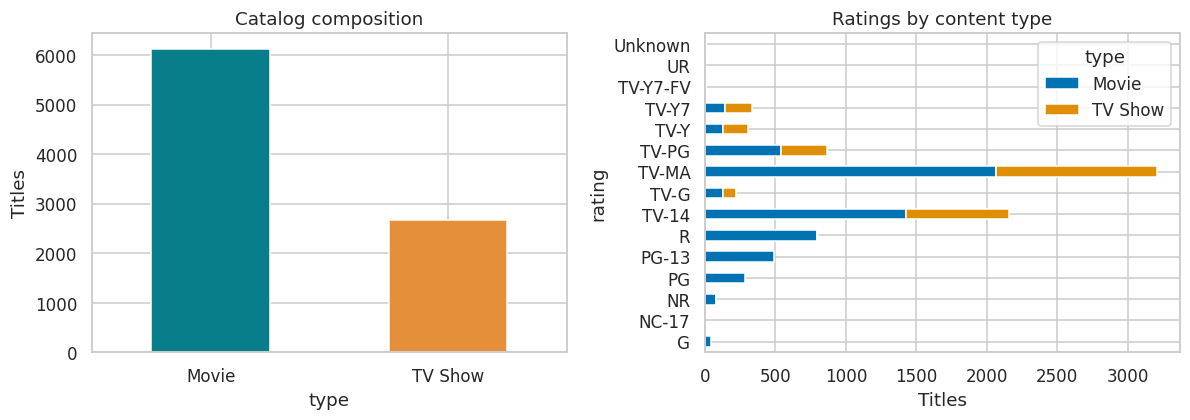

In [4]:
type_counts = shows['type'].value_counts()
type_shares = type_counts.div(len(shows)).mul(100)
display(pd.DataFrame({'titles': type_counts, 'percent': type_shares}))
display(shows[['release_year', 'added_year', 'movie_minutes', 'tv_seasons', 'valid_lag_years']].describe().T)
print('Movie runtime quartiles:', np.quantile(shows['movie_minutes'].dropna().astype(float), [0.25, 0.5, 0.75]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
type_counts.plot.bar(ax=axes[0], rot=0, color=['#087e8b', '#e58f3a'], ylabel='Titles', title='Catalog composition')
shows.groupby(['type', 'rating']).size().unstack(fill_value=0).T.plot.barh(stacked=True, ax=axes[1], title='Ratings by content type', xlabel='Titles')
save_plot('01_mix_ratings.png')


## 4. Genres, countries, directors and cast

Each title can list multiple genres, countries or people. Split comma-separated lists and count a title once per entity; resulting shares can sum to more than 100%. Unknown values are reported separately and excluded from leader rankings. Country means a listed production attribution, not subscriber location.

,title_count
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


,title_count
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


,title_count
director,
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,15
Cathy Garcia-Molina,13
Youssef Chahine,12
Martin Scorsese,12


,title_count
cast,
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Takahiro Sakurai,32
Naseeruddin Shah,32
Rupa Bhimani,31
Om Puri,30
Akshay Kumar,30
Yuki Kaji,29


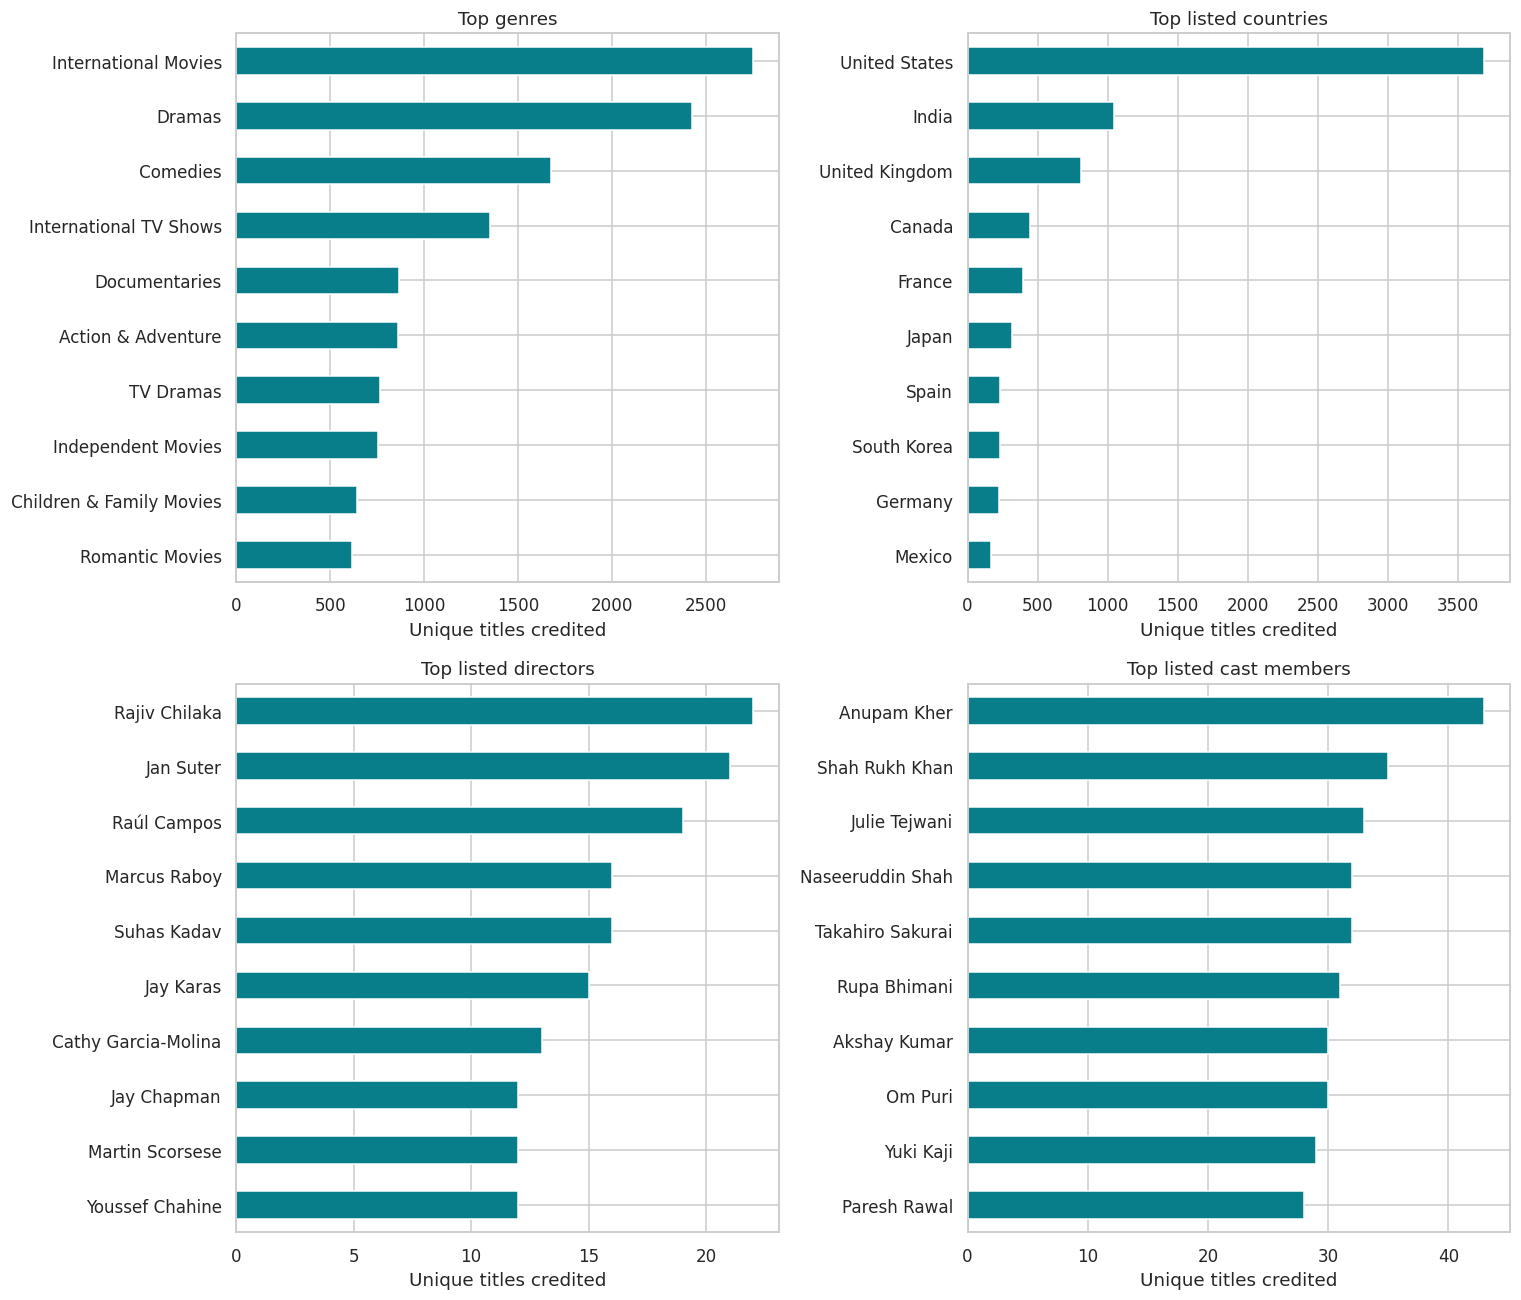

In [5]:
def entity_table(column):
    table = shows[['show_id', 'type', column]].dropna(subset=[column]).copy()
    table[column] = table[column].str.split(',')
    table = table.explode(column)
    table[column] = table[column].astype('string').str.strip()
    table = table.loc[table[column].notna() & ~table[column].isin(['', 'Unknown'])]
    return table.drop_duplicates(['show_id', column])

genres = entity_table('listed_in')
countries = entity_table('country')
directors = entity_table('director')
actors = entity_table('cast')
genre_counts = genres['listed_in'].value_counts()
country_counts = countries['country'].value_counts()
director_counts = directors['director'].value_counts()
actor_counts = actors['cast'].value_counts()
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, values, title in [(axes[0,0], genre_counts, 'Top genres'), (axes[0,1], country_counts, 'Top listed countries'),
                          (axes[1,0], director_counts, 'Top listed directors'), (axes[1,1], actor_counts, 'Top listed cast members')]:
    values.head(10).sort_values().plot.barh(ax=ax, color='#087e8b')
    ax.set(title=title, xlabel='Unique titles credited', ylabel='')
    display(values.head(10).to_frame('title_count'))
save_plot('02_entities.png')


## 5. Addition and release trends

Catalog additions are measured only for titles retained in this snapshot. They do not reconstruct historical removals or net catalog growth. The final year, 2021, is partial; compare complete years separately.

Latest addition date: 2021-09-25


type,Movie,TV Show
added_year,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,253,176


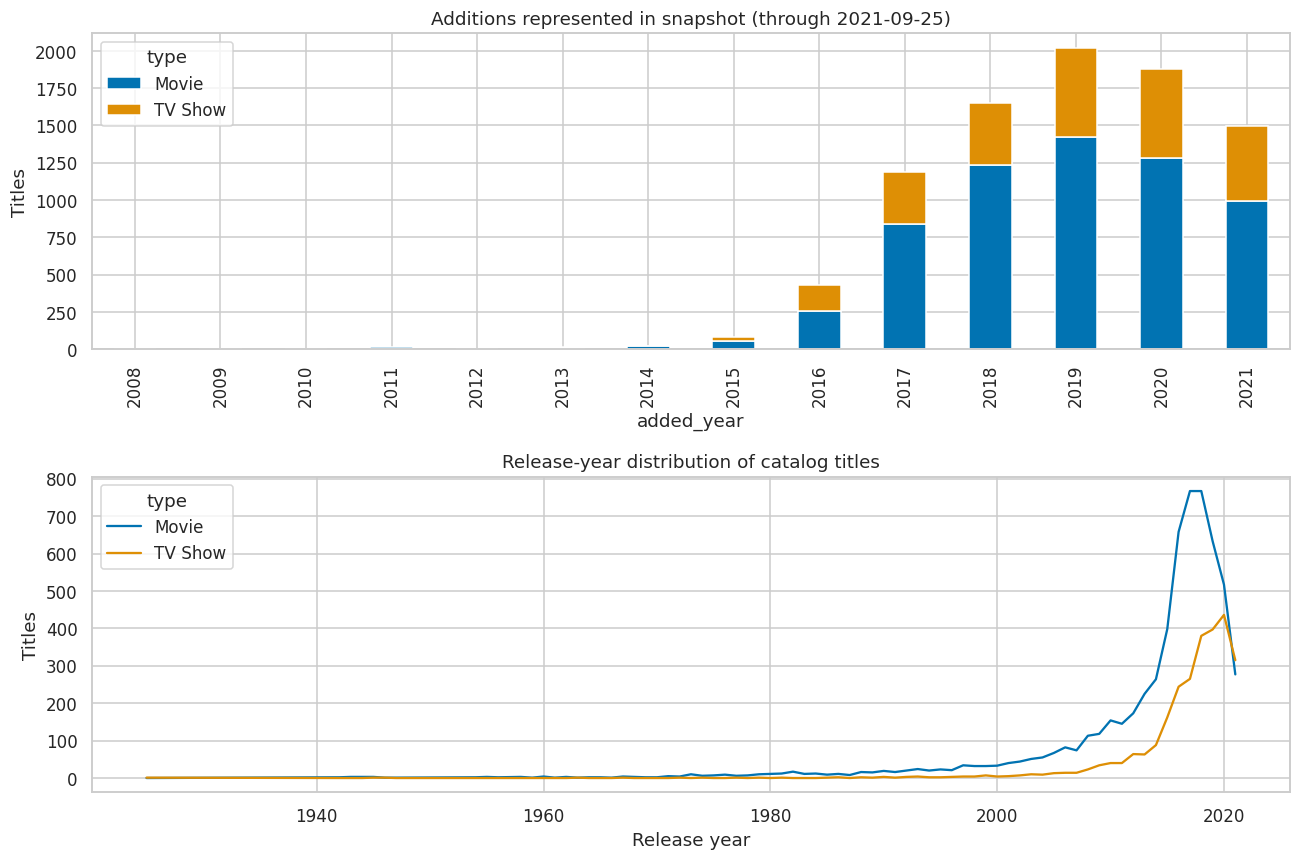

In [6]:
added = shows.dropna(subset=['date_added']).copy()
additions = added.groupby(['added_year', 'type']).size().unstack(fill_value=0).sort_index()
releases = shows.dropna(subset=['release_year']).groupby(['release_year', 'type']).size().unstack(fill_value=0).sort_index()
cutoff = added['date_added'].max()
full_years = additions.loc[additions.index < cutoff.year]
print('Latest addition date:', cutoff.date())
display(additions)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
additions.plot.bar(stacked=True, ax=axes[0], title=f'Additions represented in snapshot (through {cutoff.date()})', ylabel='Titles')
releases.plot(ax=axes[1], title='Release-year distribution of catalog titles', ylabel='Titles', xlabel='Release year')
save_plot('03_time_trends.png')


## 6. Release year, addition lag and duration

,count,median,mean
type,,,
Movie,6129,2.0,5.729972
TV Show,2654,0.0,2.314243


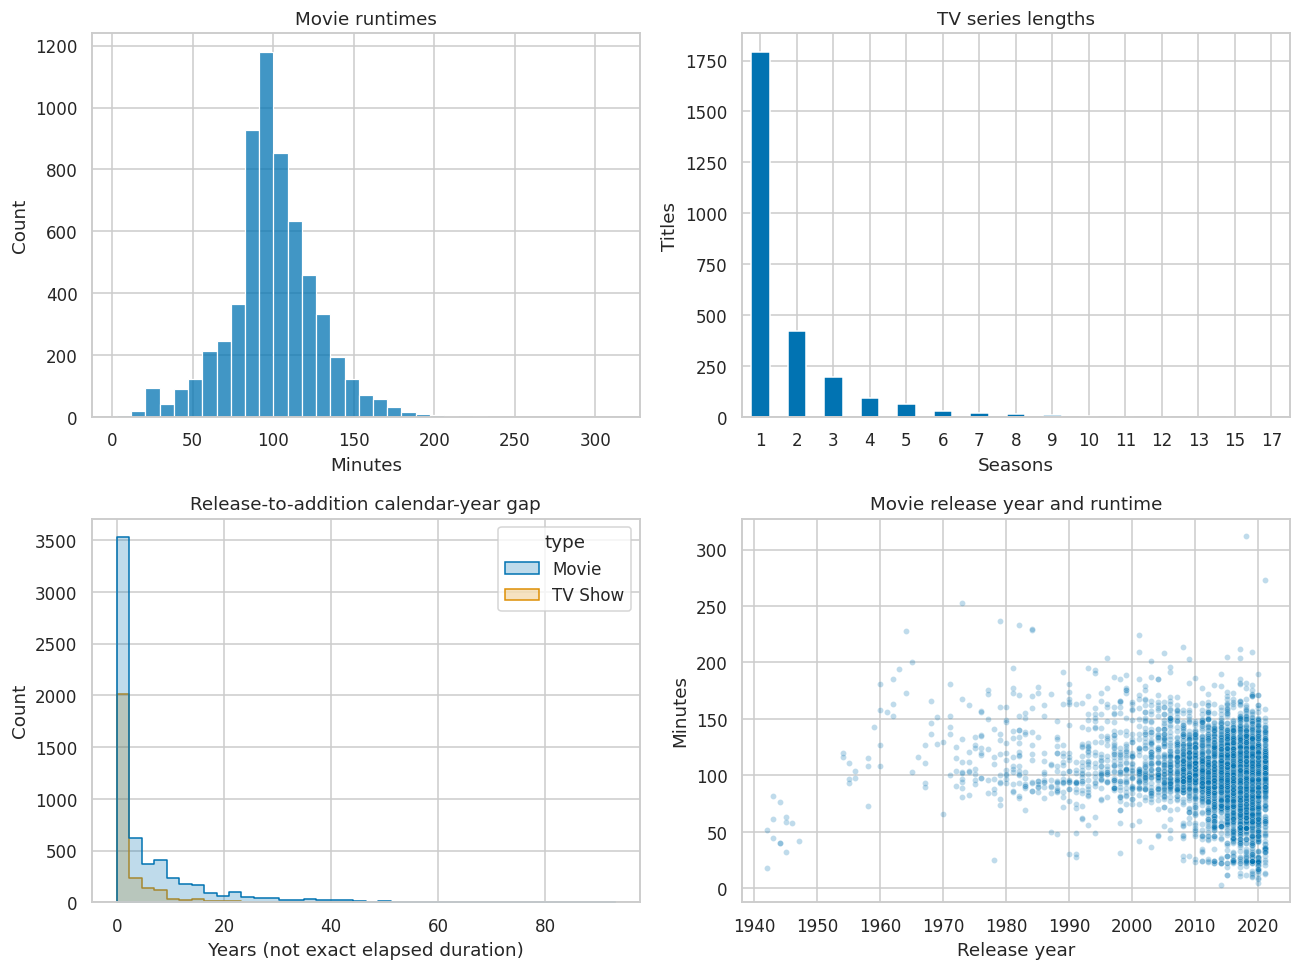

In [7]:
movies = shows.loc[shows['type'].eq('Movie') & shows['movie_minutes'].notna()].copy()
series = shows.loc[shows['type'].eq('TV Show') & shows['tv_seasons'].notna()].copy()
movie_lag = shows.loc[shows['type'].eq('Movie'), 'valid_lag_years'].dropna()
series_lag = shows.loc[shows['type'].eq('TV Show'), 'valid_lag_years'].dropna()
lag_by_type = shows.groupby('type')['valid_lag_years'].agg(['count', 'median', 'mean'])
display(lag_by_type)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(movies['movie_minutes'].astype(float), bins=35, ax=axes[0,0])
axes[0,0].set(title='Movie runtimes', xlabel='Minutes')
series['tv_seasons'].value_counts().sort_index().plot.bar(ax=axes[0,1], rot=0)
axes[0,1].set(title='TV series lengths', xlabel='Seasons', ylabel='Titles')
sns.histplot(data=shows.dropna(subset=['valid_lag_years']), x='valid_lag_years', hue='type', bins=40, element='step', ax=axes[1,0])
axes[1,0].set(title='Release-to-addition calendar-year gap', xlabel='Years (not exact elapsed duration)')
sns.scatterplot(data=movies, x='release_year', y='movie_minutes', alpha=0.25, s=15, ax=axes[1,1])
axes[1,1].set(title='Movie release year and runtime', xlabel='Release year', ylabel='Minutes')
save_plot('04_duration_lag.png')


## 7. Ratings, release dates and duration relationships

,count,median,mean
rating,,,
TV-MA,2062,96.0,95.889913
TV-14,1427,107.0,110.29082
R,797,103.0,106.720201
TV-PG,540,94.0,94.851852
PG-13,490,106.0,108.330612
PG,287,95.0,98.28223
TV-Y7,139,68.0,66.28777
TV-Y,131,46.0,48.114504
TV-G,126,84.0,79.666667


count  median
type    rating                 
Movie   G            41    17.0
        NC-17         3     3.0
        NR           75     2.0
        PG          287     8.0
        PG-13       490     9.0
        R           797     5.0
        TV-14      1427     2.0
        TV-G        126     1.0
        TV-MA      2060     1.0
        TV-PG       540     1.0
        TV-Y        131     0.0
        TV-Y7       139     2.0
        TV-Y7-FV      5     2.0
        UR            3    11.0
        Unknown       5     1.0
TV Show NR            4     4.0
        R             2     2.0
        TV-14       729     1.0
        TV-G         94     1.0
        TV-MA      1135     0.0
        TV-PG       320     1.0
        TV-Y        174     1.0
        TV-Y7       193     1.0
        TV-Y7-FV      1     1.0
        Unknown       2     3.0

,release_year,added_year,movie_minutes,valid_lag_years
release_year,1.000000,0.233317,-0.191040,-0.868756
added_year,0.233317,1.000000,0.133556,0.163450
movie_minutes,-0.191040,0.133556,1.000000,0.262755
valid_lag_years,-0.868756,0.163450,0.262755,1.000000


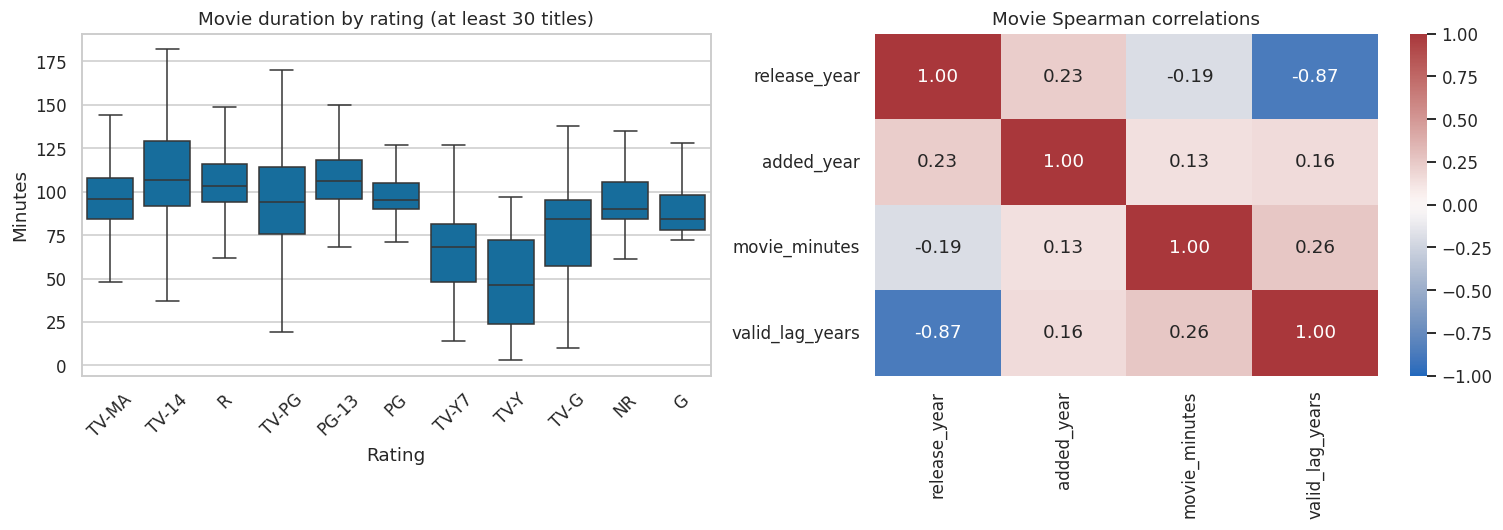

In [8]:
rating_stats = movies.groupby('rating')['movie_minutes'].agg(['count', 'median', 'mean']).sort_values('count', ascending=False)
eligible = rating_stats.loc[(rating_stats['count'] >= 30) & (rating_stats.index != 'Unknown')].index
rating_lag = shows.groupby(['type', 'rating'])['valid_lag_years'].agg(['count', 'median'])
correlation = movies[['release_year', 'added_year', 'movie_minutes', 'valid_lag_years']].astype(float).corr(method='spearman')
display(rating_stats)
display(rating_lag)
display(correlation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=movies.loc[movies['rating'].isin(eligible)], x='rating', y='movie_minutes', order=list(eligible), showfliers=False, ax=axes[0])
axes[0].set(title='Movie duration by rating (at least 30 titles)', xlabel='Rating', ylabel='Minutes')
axes[0].tick_params(axis='x', rotation=45)
sns.heatmap(correlation, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='vlag', ax=axes[1])
axes[1].set_title('Movie Spearman correlations')
save_plot('05_relationships.png')


## 8. Validation and findings

In [9]:
assert shows['show_id'].is_unique
assert len(shows) == len(raw) - exact_duplicates
assert not shows['rating'].str.fullmatch(r'\d+\s+min', na=False).any()
assert shows.loc[shows['type'].eq('TV Show'), 'movie_minutes'].isna().all()
assert shows.loc[shows['type'].eq('Movie'), 'tv_seasons'].isna().all()
assert int(type_counts.sum()) == len(shows)
assert not countries.duplicated(['show_id', 'country']).any()
assert additions.sum().sum() == shows['date_added'].notna().sum()
summary = {
 'raw_rows': len(raw), 'clean_rows': len(shows), 'movies': int(type_counts.get('Movie', 0)),
 'tv_shows': int(type_counts.get('TV Show', 0)), 'movie_share_pct': float(type_shares.get('Movie', 0)),
 'repaired_durations': repaired_count, 'missing_dates': int(shows['date_added'].isna().sum()),
 'unknown_countries': int(shows['country'].eq('Unknown').sum()), 'unknown_directors': int(shows['director'].eq('Unknown').sum()),
 'unknown_cast': int(shows['cast'].eq('Unknown').sum()), 'unknown_ratings': int(shows['rating'].eq('Unknown').sum()),
 'negative_lags': negative_lags, 'latest_addition': str(cutoff.date()),
 'top_genre': str(genre_counts.index[0]), 'top_genre_titles': int(genre_counts.iloc[0]),
 'top_country': str(country_counts.index[0]), 'top_country_titles': int(country_counts.iloc[0]),
 'top_director': str(director_counts.index[0]), 'top_director_titles': int(director_counts.iloc[0]),
 'top_cast': str(actor_counts.index[0]), 'top_cast_titles': int(actor_counts.iloc[0]),
 'peak_full_add_year': int(full_years.sum(axis=1).idxmax()), 'peak_full_add_titles': int(full_years.sum(axis=1).max()),
 'movie_minutes_median': float(movies['movie_minutes'].median()), 'tv_seasons_median': float(series['tv_seasons'].median()),
 'movie_lag_median': float(movie_lag.median()), 'tv_lag_median': float(series_lag.median()),
 'movie_year_duration_spearman': float(correlation.loc['release_year', 'movie_minutes']),
 'top_rating': str(shows['rating'].value_counts().index[0]), 'top_rating_titles': int(shows['rating'].value_counts().iloc[0])
}
(BASE / 'summary.json').write_text(json.dumps(summary, indent=2))
display(pd.Series(summary))
print(f"Movies account for {summary['movie_share_pct']:.1f}% of the {len(shows):,} titles.")
print(f"Most frequent listed genre: {summary['top_genre']} ({summary['top_genre_titles']:,} titles).")


Movies account for 69.6% of the 8,807 titles.
Most frequent listed genre: International Movies (2,752 titles).


raw_rows                                        8807
clean_rows                                      8807
movies                                          6131
tv_shows                                        2676
movie_share_pct                            69.615079
repaired_durations                                 3
missing_dates                                     10
unknown_countries                                831
unknown_directors                               2634
unknown_cast                                     825
unknown_ratings                                    7
negative_lags                                     14
latest_addition                           2021-09-25
top_genre                       International Movies
top_genre_titles                                2752
top_country                            United States
top_country_titles                              3690
top_director                           Rajiv Chilaka
top_director_titles                           

## 9. Business interpretation and limitations

- Use the movie/series mix, leading genres and country credits as a description of supply in this historical catalog, not proof of audience demand.
- Contributor rankings are incomplete because director and cast fields have missing values. Co-productions and multi-genre titles are counted once in every listed category.
- Rating categories describe intended audience/maturity, not audience review scores. Movie minutes cannot be combined with series seasons.
- Addition counts are not net catalog growth; removals and availability by subscriber market are unavailable. The final year is incomplete.
- Calendar-year gaps are approximate because exact release dates are unavailable. Negative gaps were flagged rather than changed to zero.
- Relationships are descriptive. No viewership, completion rate, licensing cost or subscription data is provided, so neither profitability nor a causal content strategy can be established.

See `Report.pdf` for the concise findings from this exact run.